# Stap 5 - PID afstellen op meetbare prestaties en gain scheduling

Je vergelijkt eerst vaste PID-instellingen en kiest daarna per doelhoek een geschikte instelling. De PID blijft op de Arduino draaien. Gain scheduling gebeurt **voor de start van een proef**, op basis van de doelhoek; er wordt tijdens de proef niet geschakeld.

Gebruik dezelfde stap 4-sketch en Python-omgeving. Sluit Serial Monitor en Plotter. Voer de meetcellen bewust per proef uit: elke meetcel start de motor. Laat de arm steeds terugkeren naar dezelfde ruststand. Houd voeding, beginhoek, meetduur, meetinterval en grenzen gelijk. Doorloop de notebook niet automatisch met 'Run All'.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from closed_loop.meting import voer_pid_meting_uit
from closed_loop.figuren import plot_pid_meting
from closed_loop.tuning import (
    lees_pid_csv, beoordeel_meting, maak_meetplan, vergelijk_metingen,
    maak_gain_schema, kies_pid,
)


## 1. Criteria en meetplan

Kies de criteria **voordat** je resultaten bekijkt. Insteltijd is het eerste geregistreerde tijdstip waarna de hoek tot het einde binnen de band blijft, met nog minimaal 5 seconden bevestiging. Overshoot wordt bepaald in de bewegingsrichting. De eindfout is de doelhoek minus de tijdgewogen gemiddelde hoek in de laatste 5 seconden. Dit is alleen een stationaire fout als dat eindinterval stabiel is.

Vul hieronder een eerder geteste PID in. Het rooster varieert Kp en Kd met -20%, 0% en +20%; Ki blijft gelijk. Als Kd nul is, kies zelf een kleine, eerder verkende reeks. Met twee doelhoeken, negen combinaties en drie herhalingen zijn dit 54 proeven: begin eventueel met een kleiner rooster. Geen enkele cel voert automatisch dit hele plan uit.

In [5]:
com_poort = "COM3"
beginhoek = 89.0  # Zelf meten in rust.

basis_pid = {"kp": 2.0, "ki": 1.0, "kd": 2.0}  # Vervang door jouw geteste instelling.
doelhoeken = [40.0, 60.0]  # Kies haalbare, eerder geteste doelhoeken.
kp_waarden = [0.8 * basis_pid["kp"], basis_pid["kp"], 1.2 * basis_pid["kp"]]
ki_waarden = [basis_pid["ki"]]
kd_waarden = [0.8 * basis_pid["kd"], basis_pid["kd"], 1.2 * basis_pid["kd"]]

meetinstellingen = dict(
    com_poort=com_poort, beginhoek=beginhoek,
    max_pwm=250, max_hoek=100.0, meetduur=10.0, delta_t=0.02,
    mode="fixed", toon_metingen=False,
)
criteria = dict(band=2.0, bevestiging_s=5.0, eindvenster_s=5.0,
                overshoot_grens=3.0, rusthoek=0.0, rusttolerantie=3.0)
herhalingen = 3
plan = pd.concat([
    maak_meetplan(hoek, kp_waarden, ki_waarden, kd_waarden, herhalingen)
    for hoek in doelhoeken
], ignore_index=True)
plan["proef"] = plan.index + 1
print(f"Aantal proeven: {len(plan)}")
display(plan)


Aantal proeven: 54


,proef,kandidaat,herhaling,doelhoek,kp,ki,kd
0,1,1,1,40.0,1.6,1.0,1.6
1,2,2,1,40.0,1.6,1.0,2.0
2,3,3,1,40.0,1.6,1.0,2.4
3,4,4,1,40.0,2.0,1.0,1.6
4,5,5,1,40.0,2.0,1.0,2.0
5,6,6,1,40.0,2.0,1.0,2.4
6,7,7,1,40.0,2.4,1.0,1.6
7,8,8,1,40.0,2.4,1.0,2.0
8,9,9,1,40.0,2.4,1.0,2.4
9,10,1,2,40.0,1.6,1.0,1.6


## 2. Een proef kiezen en uitvoeren

Verander `proefnummer` voor elke volgende proef en voer de keuzecel opnieuw uit. Controleer de getoonde instellingen en laat de arm tot rust komen voordat je de meetcel uitvoert. Het plan verhoogt het proefnummer niet automatisch.

Onderstaande bestandenlijst blijft bestaan als je de cel opnieuw uitvoert. Bewaar de lijst desgewenst als manifest zodat je later de analyse kunt hervatten. Voeg ook bestanden van afgebroken of mislukte proeven toe; die mogen niet stilzwijgend uit de vergelijking verdwijnen.

In [27]:
# Alleen kiezen: deze cel start geen motor.
proefnummer = 4
proef = plan.loc[plan["proef"] == proefnummer].iloc[0]
display(proef.to_frame("Gekozen proef"))
if "bestanden" not in globals():
    bestanden = []


,Gekozen proef
proef,4.0
kandidaat,4.0
herhaling,1.0
doelhoek,40.0
kp,2.0
ki,1.0
kd,1.6


In [28]:
# Deze cel start precies een PID-proef.
metingen, csv_pad = voer_pid_meting_uit(
    **meetinstellingen,
    doelhoek=float(proef["doelhoek"]),
    kp=float(proef["kp"]), ki=float(proef["ki"]), kd=float(proef["kd"]),
)
if csv_pad is not None:
    bestanden.append(str(csv_pad))
    bestanden = list(dict.fromkeys(bestanden))
    display(pd.Series(beoordeel_meting(csv_pad, **criteria), name="Resultaat"))


PID-meting gestart.
Meetdata en instellingen: C:\Users\jbusink1\OneDrive - HvA\Documenten\GitHub\Practica HvA Github\practicum2_2\Closed_loop\data\pid_20261030_172704_309285.csv
Aantal meetpunten: 499


bestand                C:\Users\jbusink1\OneDrive - HvA\Documenten\Gi...
com_poort                                                           COM3
doelhoek                                                            40.0
kp                                                                   2.0
ki                                                                   1.0
kd                                                                   1.6
max_pwm                                                              250
meetduur_ms                                                        10000
sensorcontrole                                                     False
regelinterval_ms                                                      20
mode                                                               fixed
max_hoek                                                           100.0
hoekoffset_deg                                                      89.0
hoekgrenzen_deg                                    

Bij een fout stopt de meetcel met een melding; ontvangen data wordt door de meetfunctie opgeslagen. Voeg het afgedrukte pad dan zelf toe, bijvoorbeeld `bestanden.append("data/pid_....csv")`. Daarna kun je onderstaande opslagcel uitvoeren.

De proef is ongeschikt bij een foutstatus, ontbrekende meetpunten, onvoldoende bevestigingstijd of overshoot boven de eis. Het eerste meetpunt dient als controle op de rustpositie, maar is geen aparte meting van de toestand vlak voor het starten.

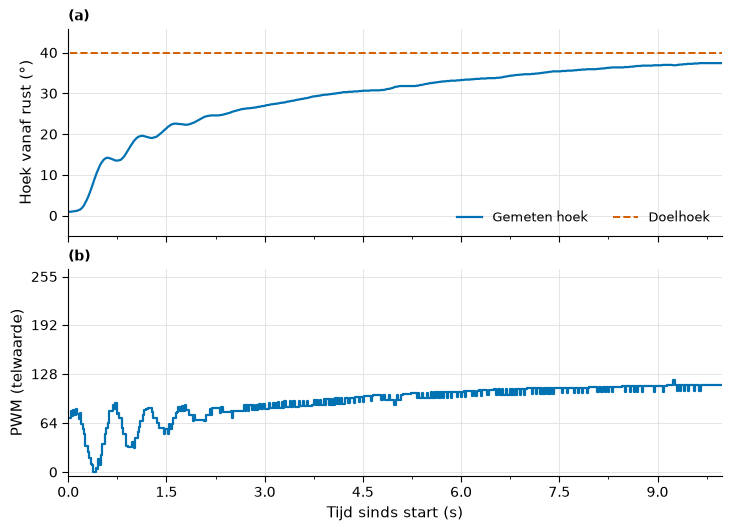

In [ ]:

Path("data").mkdir(exist_ok=True)
pd.DataFrame({"bestand": bestanden}).to_csv("data/stap5_bestanden.csv", index=False)
# Later hervatten: bestanden = pd.read_csv("data/stap5_bestanden.csv")["bestand"].tolist()

if metingen:
    fig, ax = plot_pid_meting(metingen, csv_pad=csv_pad, opslaan=False)
    plt.show()


## 3. Instellingen vergelijken

Voer dit uit zodra je meetbestanden hebt. Een combinatie is pas geschikt als er minstens drie afzonderlijke proeven zijn en **alle meegenomen herhalingen voldoen**. Gelijke bestandsnamen tellen slechts een keer. Onder geschikte combinaties wint per doelhoek de kortste mediane insteltijd; bij gelijke tijd de kleinste maximale overshoot. Bekijk ook de spreiding en PWM-verzadiging.

Verschillende meetduren, intervallen, kalibraties of grenzen mogen niet ongemerkt worden gecombineerd. De analyse weigert zulke gemengde bestanden. Gelijke voeding en mechanische begincondities moet je zelf bewaken. Bij geen geschikte instelling: bekijk `reden`, verbeter de afstelling of onderbouw een aangepaste eis, en meet opnieuw.

In [5]:
bestanden = pd.read_csv("data/stap5_bestanden.csv")["bestand"].tolist()
herhalingen = 1
criteria= dict(band=2.0, bevestiging_s=5.0, eindvenster_s=5.0,
                overshoot_grens=3.0, rusthoek=0.0, rusttolerantie=3.0)
details, ranglijst = vergelijk_metingen(
    bestanden, min_herhalingen=herhalingen, **criteria,
)
display(details[["bestand", "doelhoek", "kp", "ki", "kd", "overshoot_deg",
                 "insteltijd_s", "eindfout_deg", "eind_std_deg",
                 "iae_graden_s", "max_pwm_duur_s", "voldoet", "reden"]])
display(ranglijst)
details.to_csv("data/stap5_prestaties.csv", index=False)
ranglijst.to_csv("data/stap5_ranglijst.csv", index=False)


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\jbusink1\\OneDrive - HvA\\Documenten\\GitHub\\Practica HvA Github\\practicum2_2\\Closed_loop\\data\\pid_20261030_172021_559363.csv'

## 4. Gain scheduling op basis van de doelhoek

Maak eerst een tabel met de beste gemeten PID per doelhoek. Als een doelhoek nog geen geschikte instelling heeft, stopt de code met uitleg. Er worden geen fictieve optimale waarden ingevuld.

`dichtstbij` kiest de instelling van de dichtstbijzijnde geteste doelhoek. `lineair` interpoleert elke gain tussen twee werkpunten. Interpolatie garandeert geen goede regeling: test die combinatie opnieuw. Buiten het onderzochte hoekbereik weigert de functie een keuze. Beide methoden houden de gekozen gains gedurende de hele proef constant.

In [6]:
schema = maak_gain_schema(ranglijst)
display(schema)
schema.to_csv("data/stap5_gain_schema.csv", index=False)

# Later laden: schema = pd.read_csv("data/stap5_gain_schema.csv")
validatiehoek = 50.0  # Kies een haalbare hoek binnen het onderzochte bereik.
methode = "dichtstbij"  # Of "lineair".
geplande_pid = kies_pid(validatiehoek, schema, methode=methode)
print("PID bij deze doelhoek:", geplande_pid)


NameError: name 'ranglijst' is not defined

## 5. Valideren: vaste PID tegenover gain scheduling

Vergelijk bij dezelfde nieuwe doelhoek de oorspronkelijke vaste PID met de geplande PID. Kies hieronder eerst `vast` en later `scheduled`. Elke uitvoering van de meetcel start **een** proef. Laat de arm tussendoor tot rust komen en herhaal beide varianten minimaal drie keer. De bestandenlijst bewaart welke methode bij welke proef hoort.

Herhaal de vergelijking eventueel bij een tweede doelhoek. Als scheduling niet beter presteert, is een vaste PID een geldige uitkomst. Beoordeel dit met de afgesproken criteria; de afstelling is alleen onderzocht binnen dit werkgebied.

In [ ]:
variant = "vast"  # Wissel na de herhalingen naar "scheduled".
if variant not in ("vast", "scheduled"):
    raise ValueError("Kies vast of scheduled.")
gekozen_pid = basis_pid if variant == "vast" else kies_pid(validatiehoek, schema, methode)
print(variant, validatiehoek, gekozen_pid)
if "validatiebestanden" not in globals():
    validatiebestanden = []


In [ ]:
# Deze cel start precies een validatieproef.
validatie_metingen, validatie_pad = voer_pid_meting_uit(
    **meetinstellingen, doelhoek=validatiehoek, **gekozen_pid,
)
if validatie_pad is not None:
    validatiebestanden.append({"variant": variant, "bestand": str(validatie_pad),
                               "scheduling": methode if variant == "scheduled" else "geen"})
    pd.DataFrame(validatiebestanden).to_csv("data/stap5_validatiebestanden.csv", index=False)


Voeg bij een fout de afgedrukte bestandsnaam ook aan `validatiebestanden` toe met de juiste variant. De tabel hieronder toont de afzonderlijke resultaten; controleer of er per variant voldoende herhalingen zijn en of alle proeven voldoen.

In [ ]:
validatie = pd.DataFrame([
    {**beoordeel_meting(rij["bestand"], **criteria),
     "variant": rij["variant"], "scheduling": rij["scheduling"]}
    for rij in pd.DataFrame(validatiebestanden).drop_duplicates("bestand").to_dict("records")
])
display(validatie[["variant", "scheduling", "doelhoek", "kp", "ki", "kd",
                    "insteltijd_s", "overshoot_deg", "eindfout_deg", "voldoet", "reden"]])
validatie.to_csv("data/stap5_validatie.csv", index=False)
